# NB12: QSIPrep + MRtrix3 QC

> **Local pipeline required.** This notebook inspects QSIPrep and MRtrix3 outputs and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose
Quality control of DWI preprocessing (QSIPrep) and diffusion reconstruction
(MRtrix3 CSD, DTI, tractography). Verify distortion correction, DTI maps,
and tractography quality.

## HTML Reports
QSIPrep generates HTML reports:
```bash
open derivatives/qsiprep/sub-PAT16.html
```

## Interactive Inspection
```bash
bash scripts/freeview_dti.sh --subject PAT16 --session preop
```

## QC Checklist
- [ ] b0-to-T1w overlay shows good alignment at cortical boundaries
- [ ] Eddy correction: no residual distortion visible
- [ ] FA map: WM appears bright (0.4-0.8), GM appears dim (0.1-0.3)
- [ ] MD map: CSF appears bright, WM/GM appear intermediate
- [ ] Tractography: streamlines follow anatomically plausible paths
- [ ] No major dropout or artifact in the resection cavity region (post-op)

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
SUBJECTS = ['PAT16']
SESSIONS = ['preop', 'postop']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. QSIPrep Output Inventory

In [2]:
qsiprep_dir = DERIV_ROOT / 'qsiprep'
patterns = [
    '*_desc-preproc_dwi.nii.gz',
    '*_desc-preproc_dwi.bval',
    '*_desc-preproc_dwi.bvec',
    '*_desc-brain_mask.nii.gz',
    '*_dwiref.nii.gz',
]

for sub in SUBJECTS:
    print(f'\n=== sub-{sub} (QSIPrep) ===')
    for ses in SESSIONS:
        dwi_dir = qsiprep_dir / f'sub-{sub}' / f'ses-{ses}' / 'dwi'
        print(f'  ses-{ses}:')
        if not dwi_dir.exists():
            print('    Not yet run')
            continue
        for pat in patterns:
            matches = list(dwi_dir.glob(pat))
            mark = 'OK' if matches else '--'
            name = matches[0].name if matches else pat
            print(f'    [{mark}] {name}')


=== sub-PAT16 (QSIPrep) ===
  ses-preop:
    [OK] sub-PAT16_ses-preop_space-ACPC_desc-preproc_dwi.nii.gz
    [OK] sub-PAT16_ses-preop_space-ACPC_desc-preproc_dwi.bval
    [OK] sub-PAT16_ses-preop_space-ACPC_desc-preproc_dwi.bvec
    [OK] sub-PAT16_ses-preop_space-ACPC_desc-brain_mask.nii.gz
    [OK] sub-PAT16_ses-preop_space-ACPC_dwiref.nii.gz
  ses-postop:
    [OK] sub-PAT16_ses-postop_space-ACPC_desc-preproc_dwi.nii.gz
    [OK] sub-PAT16_ses-postop_space-ACPC_desc-preproc_dwi.bval
    [OK] sub-PAT16_ses-postop_space-ACPC_desc-preproc_dwi.bvec
    [OK] sub-PAT16_ses-postop_space-ACPC_desc-brain_mask.nii.gz
    [OK] sub-PAT16_ses-postop_space-ACPC_dwiref.nii.gz


## 2. MRtrix3 Reconstruction Inventory

In [3]:
mrtrix_dir = DERIV_ROOT / 'mrtrix_recon'
recon_files = [
    'dwi.mif', 'mask.mif',
    'wm_response.txt', 'gm_response.txt', 'csf_response.txt',
    'wm_fod_norm.mif', 'gm_fod_norm.mif', 'csf_fod_norm.mif',
    'dti.mif', 'fa.nii.gz', 'md.nii.gz', 'ad.nii.gz', 'rd.nii.gz',
    'whole_brain.tck', 'sift2_weights.txt',
]

for sub in SUBJECTS:
    print(f'\n=== sub-{sub} (MRtrix3) ===')
    for ses in SESSIONS:
        recon = mrtrix_dir / f'sub-{sub}' / f'ses-{ses}'
        print(f'  ses-{ses}:')
        if not recon.exists():
            print('    Not yet run')
            continue
        for f in recon_files:
            fp = recon / f
            if fp.exists():
                size = fp.stat().st_size / 1e6
                print(f'    [OK] {f:<25s} {size:>8.1f} MB')
            else:
                print(f'    [--] {f}')


=== sub-PAT16 (MRtrix3) ===
  ses-preop:
    [OK] dwi.mif                     2256.2 MB
    [OK] mask.mif                       5.4 MB
    [OK] wm_response.txt                0.0 MB
    [OK] gm_response.txt                0.0 MB
    [OK] csf_response.txt               0.0 MB
    [OK] wm_fod_norm.mif              976.3 MB
    [OK] gm_fod_norm.mif               21.7 MB
    [OK] csf_fod_norm.mif              21.7 MB
    [OK] dti.mif                      130.2 MB
    [OK] fa.nii.gz                      5.7 MB
    [OK] md.nii.gz                      5.7 MB
    [OK] ad.nii.gz                      5.6 MB
    [OK] rd.nii.gz                      5.7 MB
    [OK] whole_brain.tck             7693.7 MB
    [OK] sift2_weights.txt            124.8 MB
  ses-postop:
    [OK] dwi.mif                     2256.2 MB
    [OK] mask.mif                       5.4 MB
    [OK] wm_response.txt                0.0 MB
    [OK] gm_response.txt                0.0 MB
    [OK] csf_response.txt               0.0 MB
    

## 3. DTI Map Visualization

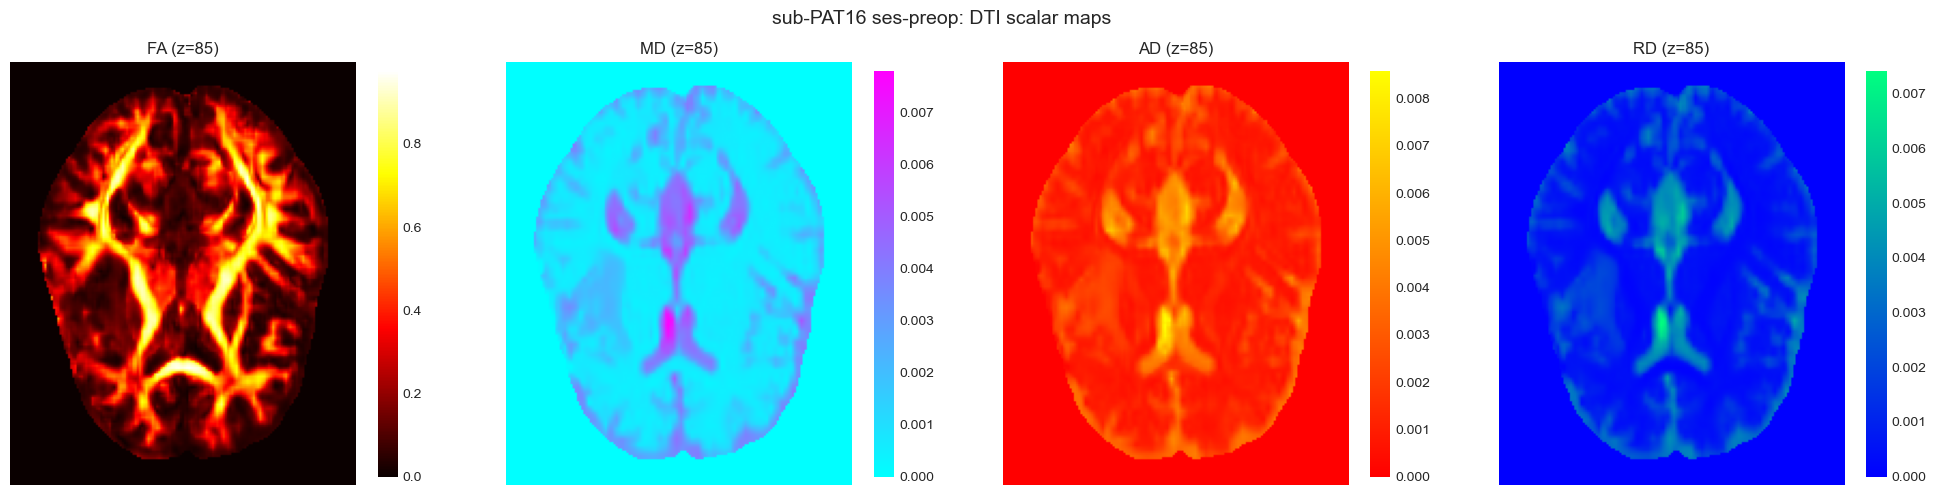

  FA: mean=0.2470, std=0.2110, range=[0.0016, 1.2247]
  MD: mean=0.0016, std=0.0012, range=[0.0000, 0.0088]
  AD: mean=0.0019, std=0.0013, range=[0.0000, 0.0115]
  RD: mean=0.0014, std=0.0012, range=[0.0000, 0.0082]


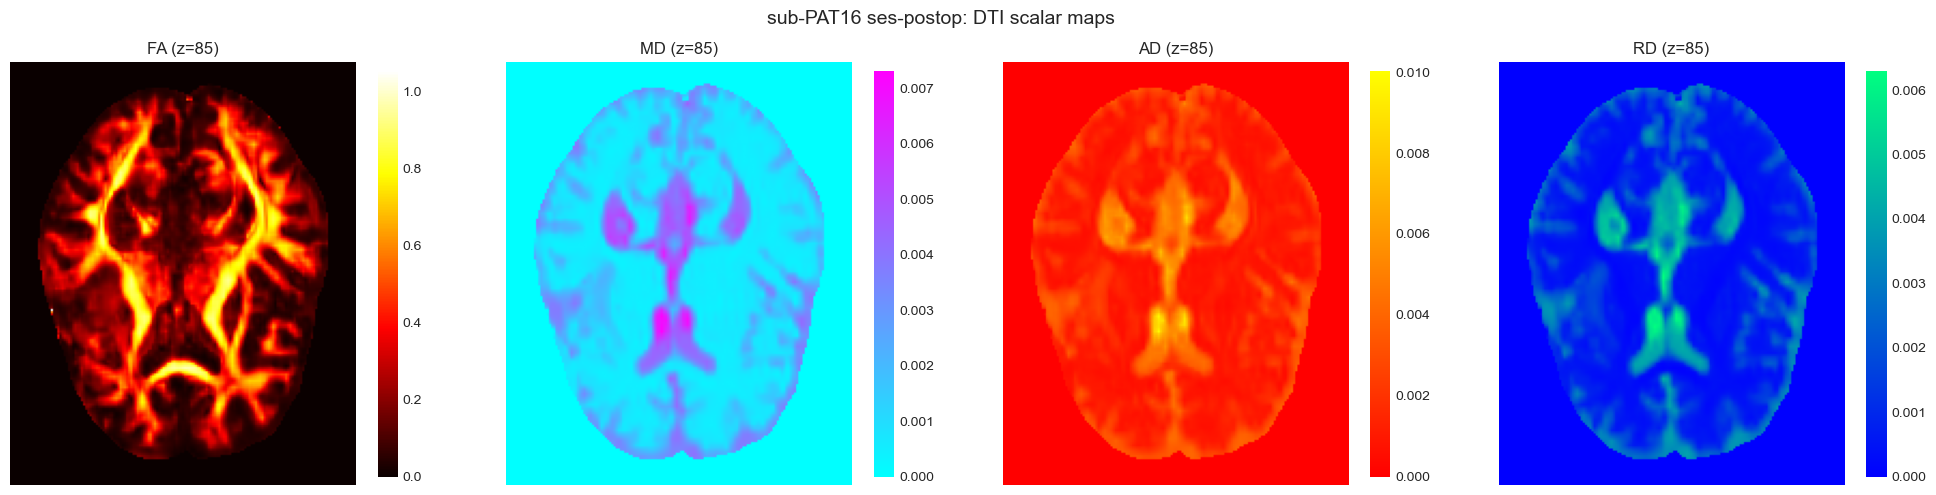

  FA: mean=0.2452, std=0.2135, range=[0.0027, 1.2247]
  MD: mean=0.0017, std=0.0013, range=[0.0000, 0.0091]
  AD: mean=0.0020, std=0.0013, range=[0.0000, 0.0118]
  RD: mean=0.0015, std=0.0012, range=[0.0000, 0.0083]


In [4]:
try:
    import nibabel as nib

    metrics = ['fa', 'md', 'ad', 'rd']
    cmaps = ['hot', 'cool', 'autumn', 'winter']
    titles = ['FA', 'MD', 'AD', 'RD']

    for sub in SUBJECTS:
        for ses in SESSIONS:
            recon = mrtrix_dir / f'sub-{sub}' / f'ses-{ses}'
            fa_path = recon / 'fa.nii.gz'
            if not fa_path.exists():
                continue

            fig, axes = plt.subplots(1, 4, figsize=(20, 5))
            fig.suptitle(f'sub-{sub} ses-{ses}: DTI scalar maps', fontsize=14)

            for idx, (metric, cmap, title) in enumerate(zip(metrics, cmaps, titles)):
                path = recon / f'{metric}.nii.gz'
                if path.exists():
                    data = np.asarray(nib.load(str(path)).dataobj)
                    mid = data.shape[2] // 2
                    sl = np.rot90(data[:, :, mid])
                    im = axes[idx].imshow(sl, cmap=cmap)
                    axes[idx].set_title(f'{title} (z={mid})')
                    plt.colorbar(im, ax=axes[idx], fraction=0.046)
                else:
                    axes[idx].text(0.5, 0.5, 'Missing', ha='center',
                                  va='center', transform=axes[idx].transAxes)
                    axes[idx].set_title(title)
                axes[idx].axis('off')

            plt.tight_layout()
            plt.show()

            # Print summary statistics
            for metric, title in zip(metrics, titles):
                path = recon / f'{metric}.nii.gz'
                if path.exists():
                    data = np.asarray(nib.load(str(path)).dataobj)
                    mask = np.isfinite(data) & (data > 0)
                    if mask.sum() > 0:
                        vals = data[mask]
                        print(f'  {title}: mean={np.mean(vals):.4f}, '
                              f'std={np.std(vals):.4f}, '
                              f'range=[{np.min(vals):.4f}, {np.max(vals):.4f}]')

except Exception as e:
    print(f'DTI visualization not available: {e}')

## 4. Response Functions

The tissue response functions estimated by dhollander should show characteristic
patterns: WM response is elongated (anisotropic), GM is nearly isotropic,
and CSF is a single sharp peak.

In [5]:
for sub in SUBJECTS:
    for ses in SESSIONS:
        recon = mrtrix_dir / f'sub-{sub}' / f'ses-{ses}'
        print(f'\nsub-{sub} ses-{ses}:')
        for tissue in ['wm', 'gm', 'csf']:
            resp_path = recon / f'{tissue}_response.txt'
            if resp_path.exists():
                with open(resp_path) as f:
                    lines = f.readlines()
                n_shells = len(lines)
                print(f'  {tissue}: {n_shells} shell(s)')
                for i, line in enumerate(lines[:3]):
                    print(f'    shell {i}: {line.strip()}')
            else:
                print(f'  {tissue}: not available')


sub-PAT16 ses-preop:
  wm: 6 shell(s)
    shell 0: # Shells: 0,500,1000,3000
    shell 1: # command_history: ~/mrtrix3/bin/amp2response dwi.mif voxels_sfwm.mif safe_vecs.mif response_sfwm.txt -shells '0,500,1000,3000' -nthreads 8  (version=3.0.8-21-g8b3d398a)
    shell 2: 409.287738681209 0 0 0 0 0
  gm: 6 shell(s)
    shell 0: # Shells: 0,500,1000,3000
    shell 1: # command_history: ~/mrtrix3/bin/amp2response dwi.mif voxels_gm.mif safe_vecs.mif response_gm.txt -shells '0,500,1000,3000' -isotropic -nthreads 8  (version=3.0.8-21-g8b3d398a)
    shell 2: 1041.68661285657
  csf: 6 shell(s)
    shell 0: # Shells: 0,500,1000,3000
    shell 1: # command_history: ~/mrtrix3/bin/amp2response dwi.mif voxels_csf.mif safe_vecs.mif response_csf.txt -shells '0,500,1000,3000' -isotropic -nthreads 8  (version=3.0.8-21-g8b3d398a)
    shell 2: 3112.58093023905

sub-PAT16 ses-postop:
  wm: 6 shell(s)
    shell 0: # Shells: 0,500,1000,3000
    shell 1: # command_history: ~/mrtrix3/bin/amp2response dwi.mi

## 5. Tractography Summary

For interactive tractography inspection, use mrview or freeview:
```bash
mrview derivatives/mrtrix_recon/sub-PAT16/ses-preop/fa.nii.gz \
    -tractography.load derivatives/mrtrix_recon/sub-PAT16/ses-preop/whole_brain.tck
```

In [6]:
for sub in SUBJECTS:
    print(f'\n=== sub-{sub} ===')
    for ses in SESSIONS:
        recon = mrtrix_dir / f'sub-{sub}' / f'ses-{ses}'
        tck_path = recon / 'whole_brain.tck'
        sift2_path = recon / 'sift2_weights.txt'

        if tck_path.exists():
            size_gb = tck_path.stat().st_size / 1e9
            print(f'  ses-{ses}: whole_brain.tck = {size_gb:.2f} GB')
            if sift2_path.exists():
                with open(sift2_path) as f:
                    n_weights = sum(1 for _ in f)
                print(f'           sift2_weights.txt = {n_weights} streamlines')
        else:
            print(f'  ses-{ses}: not yet run')


=== sub-PAT16 ===
  ses-preop: whole_brain.tck = 7.69 GB


           sift2_weights.txt = 2 streamlines
  ses-postop: whole_brain.tck = 8.02 GB
           sift2_weights.txt = 2 streamlines
